In [459]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy import polyfit, polyval
import statsmodels.api as sm
from matplotlib.ticker import MultipleLocator
import scipy.signal as signal
from scipy import stats
import sympy as sp
from scipy.signal import savgol_filter
from scipy.signal import find_peaks
from scipy.interpolate import interp1d
from scipy.ndimage import maximum_filter1d
from scipy.interpolate import UnivariateSpline
from matplotlib.patches import Ellipse

In [407]:
def AreaCalc(index_step,elev,continuum,dist,top, bottom):
    """
    Calculates de area of each bin as if it's a Riemann sum and the centered location of each bin
    index_step: step for each iteration to change the index
    elev: list of elevations of the topographic profile
    continuum: list of "elevations" of the continuum
    dist: list for the x axis of the topographic profile and the continuum
    """
    i=0
    areas=[] #Output list of the value calculated of the area for each step
    locations=[] # Output list to record to what distance does each area belong
    while i<(len(elev)-1):
        if elev[i]<=top:
            #print(elev[i],continuum[i])
            if elev[i]>bottom and continuum[i]<top:
                height=np.abs(continuum[i]-elev[i])
            elif elev[i]>bottom and continuum[i]>top:
                height=np.abs(top-elev[i])
            elif elev[i]<bottom and continuum[i]<top:
                height=np.abs(continuum[i]-bottom)
            elif elev[i]<bottom and continuum[i]>top:
                height=np.abs(top-bottom)
            else:
                height=0
            if height>0.01:
                right=i+index_step
                area=height*((dist[right]-dist[i])) #Calculates area of each bin
                i+=index_step
            else:
                area=0
                i+=1
            areas.append(area)
            locations.append(dist[i])
            if elev[i]<bottom and continuum[i]<bottom:
                break
        else:
            i+=1
    return areas, locations
    

In [408]:
len(elevAd_Ja2012)

352

In [409]:
#G1
topAa_1='../Antarctica_a1Prof.csv'
SAa_1=pd.read_csv(topAa_1)
distAa_1=np.array(SAa_1['distance'].tolist())
elevAa_1= np.array(SAa_1['elevation'].tolist())
topAa_2='../Antarctica_a2Prof.csv'
SAa_2=pd.read_csv(topAa_2)
distAa_2=np.array(SAa_2['distance'].tolist())
elevAa_2= np.array(SAa_2['elevation'].tolist())
topAa_3='../Antarctica_a3Prof.csv'
SAa_3=pd.read_csv(topAa_3)
distAa_3=np.array(SAa_3['distance'].tolist())
elevAa_3= np.array(SAa_3['elevation'].tolist())
topAa_4='../Antarctica_a4Prof.csv'
SAa_4=pd.read_csv(topAa_4)
distAa_4=np.array(SAa_4['distance'].tolist())
elevAa_4= np.array(SAa_4['elevation'].tolist())


topAb_1='../Antarctica_b1Prof.csv'
SAb_1=pd.read_csv(topAb_1)
distAb_1=np.array(SAb_1['distance'].tolist())
elevAb_1= np.array(SAb_1['elevation'].tolist())
topAb_2='../Antarctica_b2Prof.csv'
SAb_2=pd.read_csv(topAb_2)
distAb_2=np.array(SAb_2['distance'].tolist())
elevAb_2= np.array(SAb_2['elevation'].tolist())
topAb_3='../Antarctica_b3Prof.csv'
SAb_3=pd.read_csv(topAb_3)
distAb_3=np.array(SAb_3['distance'].tolist())
elevAb_3= np.array(SAb_3['elevation'].tolist())
topAb_43='../Antarctica_b4Prof.csv'
SAb_4=pd.read_csv(topAb_4)
distAb_4=np.array(SAb_4['distance'].tolist())
elevAb_4= np.array(SAb_4['elevation'].tolist())

topAc_1='../Antarctica_c1Prof.csv'
SAc_1=pd.read_csv(topAc_1)
distAc_1=np.array(SAc_1['distance'].tolist())
elevAc_1= np.array(SAc_1['elevation'].tolist())
topAc_2='../Antarctica_c2Prof.csv'
SAc_2=pd.read_csv(topAc_2)
distAc_2=np.array(SAc_2['distance'].tolist())
elevAc_2= np.array(SAc_2['elevation'].tolist())
topAc_3='../Antarctica_c3Prof.csv'
SAc_3=pd.read_csv(topAc_3)
distAc_3=np.array(SAc_3['distance'].tolist())
elevAc_3= np.array(SAc_3['elevation'].tolist())
topAc_4='../Antarctica_c4Prof.csv'
SAc_4=pd.read_csv(topAc_4)
distAc_4=np.array(SAc_4['distance'].tolist())
elevAc_4= np.array(SAc_4['elevation'].tolist())

topAd_1='../Antarctica_d1Prof.csv'
SAd_1=pd.read_csv(topAd_1)
distAd_1=np.array(SAd_1['distance'].tolist())
elevAd_1= np.array(SAd_1['elevation'].tolist())
topAd_2='../Antarctica_d2Prof.csv'
SAd_2=pd.read_csv(topAd_2)
distAd_2=np.array(SAd_2['distance'].tolist())
elevAd_2= np.array(SAd_2['elevation'].tolist())
topAd_3='../Antarctica_d3Prof.csv'
SAd_3=pd.read_csv(topAd_3)
distAd_3=np.array(SAd_3['distance'].tolist())
elevAd_3= np.array(SAd_3['elevation'].tolist())
topAd_4='../Antarctica_d4Prof.csv'
SAd_4=pd.read_csv(topAd_4)
distAd_4=np.array(SAd_4['distance'].tolist())
elevAd_4= np.array(SAd_4['elevation'].tolist())

topAe_1='../Antarctica_e1Prof.csv'
SAe_1=pd.read_csv(topAe_1)
distAe_1=np.array(SAe_1['distance'].tolist())
elevAe_1= np.array(SAe_1['elevation'].tolist())
topAe_2='../Antarctica_e2Prof.csv'
SAe_2=pd.read_csv(topAe_2)
distAe_2=np.array(SAe_2['distance'].tolist())
elevAe_2= np.array(SAe_2['elevation'].tolist())
topAe_3='../Antarctica_e3Prof.csv'
SAe_3=pd.read_csv(topAe_3)
distAe_3=np.array(SAe_3['distance'].tolist())
elevAe_3= np.array(SAe_3['elevation'].tolist())
topAe_4='../Antarctica_e4Prof.csv'
SAe_4=pd.read_csv(topAe_4)
distAe_4=np.array(SAe_4['distance'].tolist())
elevAe_4= np.array(SAe_4['elevation'].tolist())

#G2

topAf_1='../Antarctica_f1Prof.csv'
SAf_1=pd.read_csv(topAf_1)
distAf_1=np.array(SAf_1['distance'].tolist())
elevAf_1= np.array(SAf_1['elevation'].tolist())
topAf_2='../Antarctica_f2Prof.csv'
SAf_2=pd.read_csv(topAf_2)
distAf_2=np.array(SAf_2['distance'].tolist())
elevAf_2= np.array(SAf_2['elevation'].tolist())
topAf_3='../Antarctica_f3Prof.csv'
SAf_3=pd.read_csv(topAf_3)
distAf_3=np.array(SAf_3['distance'].tolist())
elevAf_3= np.array(SAf_3['elevation'].tolist())
topAf_4='../Antarctica_f4Prof.csv'
SAf_4=pd.read_csv(topAf_4)
distAf_4=np.array(SAf_4['distance'].tolist())
elevAf_4= np.array(SAf_4['elevation'].tolist())

topAg_1='../Antarctica_g1Prof.csv'
SAg_1=pd.read_csv(topAg_1)
distAg_1=np.array(SAg_1['distance'].tolist())
elevAg_1= np.array(SAg_1['elevation'].tolist())
topAg_2='../Antarctica_g2Prof.csv'
SAg_2=pd.read_csv(topAg_2)
distAg_2=np.array(SAg_2['distance'].tolist())
elevAg_2= np.array(SAg_2['elevation'].tolist())
topAg_3='../Antarctica_g3Prof.csv'
SAg_3=pd.read_csv(topAg_3)
distAg_3=np.array(SAg_3['distance'].tolist())
elevAg_3= np.array(SAg_3['elevation'].tolist())
topAg_4='../Antarctica_g4Prof.csv'
SAg_4=pd.read_csv(topAg_4)
distAg_4=np.array(SAg_4['distance'].tolist())
elevAg_4= np.array(SAg_4['elevation'].tolist())

topAh_1='../Antarctica_h1Prof.csv'
SAh_1=pd.read_csv(topAh_1)
distAh_1=np.array(SAh_1['distance'].tolist())
elevAh_1= np.array(SAh_1['elevation'].tolist())
topAh_2='../Antarctica_h2Prof.csv'
SAh_2=pd.read_csv(topAh_2)
distAh_2=np.array(SAh_2['distance'].tolist())
elevAh_2= np.array(SAh_2['elevation'].tolist())
topAh_3='../Antarctica_h3Prof.csv'
SAh_3=pd.read_csv(topAh_3)
distAh_3=np.array(SAh_3['distance'].tolist())
elevAh_3= np.array(SAh_3['elevation'].tolist())
topAh_4='../Antarctica_h4Prof.csv'
SAh_4=pd.read_csv(topAh_4)
distAh_4=np.array(SAh_4['distance'].tolist())
elevAh_4= np.array(SAh_4['elevation'].tolist())

topAi_1='../Antarctica_i1Prof.csv'
SAi_1=pd.read_csv(topAi_1)
distAi_1=np.array(SAi_1['distance'].tolist())
elevAi_1= np.array(SAi_1['elevation'].tolist())
topAi_2='../Antarctica_i2Prof.csv'
SAi_2=pd.read_csv(topAi_2)
distAi_2=np.array(SAi_2['distance'].tolist())
elevAi_2= np.array(SAi_2['elevation'].tolist())
topAi_3='../Antarctica_i3Prof.csv'
SAi_3=pd.read_csv(topAi_3)
distAi_3=np.array(SAi_3['distance'].tolist())
elevAi_3= np.array(SAi_3['elevation'].tolist())
topAi_4='../Antarctica_i4Prof.csv'
SAi_4=pd.read_csv(topAi_4)
distAi_4=np.array(SAi_4['distance'].tolist())
elevAi_4= np.array(SAi_4['elevation'].tolist())

topAj_1='../Antarctica_j1Prof.csv'
SAj_1=pd.read_csv(topAj_1)
distAj_1=np.array(SAj_1['distance'].tolist())
elevAj_1= np.array(SAj_1['elevation'].tolist())
topAj_2='../Antarctica_j2Prof.csv'
SAj_2=pd.read_csv(topAj_2)
distAj_2=np.array(SAj_2['distance'].tolist())
elevAj_2= np.array(SAj_2['elevation'].tolist())
topAj_3='../Antarctica_j3Prof.csv'
SAj_3=pd.read_csv(topAj_3)
distAj_3=np.array(SAj_3['distance'].tolist())
elevAj_3= np.array(SAj_3['elevation'].tolist())
topAj_4='../Antarctica_j4Prof.csv'
SAj_4=pd.read_csv(topAj_4)
distAj_4=np.array(SAj_4['distance'].tolist())
elevAj_4= np.array(SAj_4['elevation'].tolist())

#G3

topAk_1='../Antarctica_k1Prof.csv'
SAk_1=pd.read_csv(topAk_1)
distAk_1=np.array(SAk_1['distance'].tolist())
elevAk_1= np.array(SAk_1['elevation'].tolist())
topAk_2='../Antarctica_k2Prof.csv'
SAk_2=pd.read_csv(topAk_2)
distAk_2=np.array(SAk_2['distance'].tolist())
elevAk_2= np.array(SAk_2['elevation'].tolist())
topAk_3='../Antarctica_k3Prof.csv'
SAk_3=pd.read_csv(topAk_3)
distAk_3=np.array(SAk_3['distance'].tolist())
elevAk_3= np.array(SAk_3['elevation'].tolist())
topAk_4='../Antarctica_k4Prof.csv'
SAk_4=pd.read_csv(topAk_4)
distAk_4=np.array(SAk_4['distance'].tolist())
elevAk_4= np.array(SAk_4['elevation'].tolist())

topAl_1='../Antarctica_l1Prof.csv'
SAl_1=pd.read_csv(topAl_1)
distAl_1=np.array(SAl_1['distance'].tolist())
elevAl_1= np.array(SAl_1['elevation'].tolist())
topAl_2='../Antarctica_l2Prof.csv'
SAl_2=pd.read_csv(topAl_2)
distAl_2=np.array(SAl_2['distance'].tolist())
elevAl_2= np.array(SAl_2['elevation'].tolist())
topAl_3='../Antarctica_l3Prof.csv'
SAl_3=pd.read_csv(topAl_3)
distAl_3=np.array(SAl_3['distance'].tolist())
elevAl_3= np.array(SAl_3['elevation'].tolist())
topAl_4='../Antarctica_l4Prof.csv'
SAl_4=pd.read_csv(topAl_4)
distAl_4=np.array(SAl_4['distance'].tolist())
elevAl_4= np.array(SAl_4['elevation'].tolist())

topAm_1='../Antarctica_m1Prof.csv'
SAm_1=pd.read_csv(topAm_1)
distAm_1=np.array(SAm_1['distance'].tolist())
elevAm_1= np.array(SAm_1['elevation'].tolist())
topAm_2='../Antarctica_m2Prof.csv'
SAm_2=pd.read_csv(topAm_2)
distAm_2=np.array(SAm_2['distance'].tolist())
elevAm_2= np.array(SAm_2['elevation'].tolist())
topAm_3='../Antarctica_m3Prof.csv'
SAm_3=pd.read_csv(topAm_3)
distAm_3=np.array(SAm_3['distance'].tolist())
elevAm_3= np.array(SAm_3['elevation'].tolist())
topAm_4='../Antarctica_m4Prof.csv'
SAm_4=pd.read_csv(topAm_4)
distAm_4=np.array(SAm_4['distance'].tolist())
elevAm_4= np.array(SAm_4['elevation'].tolist())

#G4

topAn_1='../Antarctica_n1Prof.csv'
SAn_1=pd.read_csv(topAn_1)
distAn_1=np.array(SAn_1['distance'].tolist())
elevAn_1= np.array(SAn_1['elevation'].tolist())
topAn_2='../Antarctica_n2Prof.csv'
SAn_2=pd.read_csv(topAn_2)
distAn_2=np.array(SAn_2['distance'].tolist())
elevAn_2= np.array(SAn_2['elevation'].tolist())
topAn_3='../Antarctica_n3Prof.csv'
SAn_3=pd.read_csv(topAn_3)
distAn_3=np.array(SAn_3['distance'].tolist())
elevAn_3= np.array(SAn_3['elevation'].tolist())
topAn_4='../Antarctica_n4Prof.csv'
SAn_4=pd.read_csv(topAn_4)
distAn_4=np.array(SAn_4['distance'].tolist())
elevAn_4= np.array(SAn_4['elevation'].tolist())

topAo_1='../Antarctica_o1Prof.csv'
SAo_1=pd.read_csv(topAo_1)
distAo_1=np.array(SAo_1['distance'].tolist())
elevAo_1= np.array(SAo_1['elevation'].tolist())
topAo_2='../Antarctica_o2Prof.csv'
SAo_2=pd.read_csv(topAo_2)
distAo_2=np.array(SAo_2['distance'].tolist())
elevAo_2= np.array(SAo_2['elevation'].tolist())
topAo_3='../Antarctica_o3Prof.csv'
SAo_3=pd.read_csv(topAo_3)
distAo_3=np.array(SAo_3['distance'].tolist())
elevAo_3= np.array(SAo_3['elevation'].tolist())
topAo_4='../Antarctica_o4Prof.csv'
SAo_4=pd.read_csv(topAo_4)
distAo_4=np.array(SAo_4['distance'].tolist())
elevAo_4= np.array(SAo_4['elevation'].tolist())

topAp_1='../Antarctica_p1Prof.csv'
SAp_1=pd.read_csv(topAp_1)
distAp_1=np.array(SAp_1['distance'].tolist())
elevAp_1= np.array(SAp_1['elevation'].tolist())
topAp_2='../Antarctica_p2Prof.csv'
SAp_2=pd.read_csv(topAp_2)
distAp_2=np.array(SAp_2['distance'].tolist())
elevAp_2= np.array(SAp_2['elevation'].tolist())
topAp_3='../Antarctica_p3Prof.csv'
SAp_3=pd.read_csv(topAp_3)
distAp_3=np.array(SAp_3['distance'].tolist())
elevAp_3= np.array(SAp_3['elevation'].tolist())
topAp_4='../Antarctica_p4Prof.csv'
SAp_4=pd.read_csv(topAp_4)
distAp_4=np.array(SAp_4['distance'].tolist())
elevAp_4= np.array(SAp_4['elevation'].tolist())

topAq_1='../Antarctica_q1Prof.csv'
SAq_1=pd.read_csv(topAq_1)
distAq_1=np.array(SAq_1['distance'].tolist())
elevAq_1= np.array(SAq_1['elevation'].tolist())
topAq_2='../Antarctica_q2Prof.csv'
SAq_2=pd.read_csv(topAq_2)
distAq_2=np.array(SAq_2['distance'].tolist())
elevAq_2= np.array(SAq_2['elevation'].tolist())
topAq_3='../Antarctica_q3Prof.csv'
SAq_3=pd.read_csv(topAq_3)
distAq_3=np.array(SAq_3['distance'].tolist())
elevAq_3= np.array(SAq_3['elevation'].tolist())
topAq_4='../Antarctica_q4Prof.csv'
SAq_4=pd.read_csv(topAq_4)
distAq_4=np.array(SAq_4['distance'].tolist())
elevAq_4= np.array(SAq_4['elevation'].tolist())

topAr_1='../Antarctica_r1Prof.csv'
SAr_1=pd.read_csv(topAr_1)
distAr_1=np.array(SAr_1['distance'].tolist())
elevAr_1= np.array(SAr_1['elevation'].tolist())
topAr_2='../Antarctica_r2Prof.csv'
SAr_2=pd.read_csv(topAr_2)
distAr_2=np.array(SAr_2['distance'].tolist())
elevAr_2= np.array(SAr_2['elevation'].tolist())
topAr_3='../Antarctica_r3Prof.csv'
SAr_3=pd.read_csv(topAr_3)
distAr_3=np.array(SAr_3['distance'].tolist())
elevAr_3= np.array(SAr_3['elevation'].tolist())
topAr_4='../Antarctica_r4Prof.csv'
SAr_4=pd.read_csv(topAr_4)
distAr_4=np.array(SAr_4['distance'].tolist())
elevAr_4= np.array(SAr_4['elevation'].tolist())

topAs_1='../Antarctica_s1Prof.csv'
SAs_1=pd.read_csv(topAs_1)
distAs_1=np.array(SAs_1['distance'].tolist())
elevAs_1= np.array(SAs_1['elevation'].tolist())
topAs_2='../Antarctica_s2Prof.csv'
SAs_2=pd.read_csv(topAs_2)
distAs_2=np.array(SAs_2['distance'].tolist())
elevAs_2= np.array(SAs_2['elevation'].tolist())
topAs_3='../Antarctica_s3Prof.csv'
SAs_3=pd.read_csv(topAs_3)
distAs_3=np.array(SAs_3['distance'].tolist())
elevAs_3= np.array(SAs_3['elevation'].tolist())
topAs_4='../Antarctica_s4Prof.csv'
SAs_4=pd.read_csv(topAs_4)
distAs_4=np.array(SAs_4['distance'].tolist())
elevAs_4= np.array(SAs_4['elevation'].tolist())

topAt_1='../Antarctica_t1Prof.csv'
SAt_1=pd.read_csv(topAt_1)
distAt_1=np.array(SAt_1['distance'].tolist())
elevAt_1= np.array(SAt_1['elevation'].tolist())
topAt_2='../Antarctica_t2Prof.csv'
SAt_2=pd.read_csv(topAt_2)
distAt_2=np.array(SAt_2['distance'].tolist())
elevAt_2= np.array(SAt_2['elevation'].tolist())
topAt_3='../Antarctica_t3Prof.csv'
SAt_3=pd.read_csv(topAt_3)
distAt_3=np.array(SAt_3['distance'].tolist())
elevAt_3= np.array(SAt_3['elevation'].tolist())
topAt_4='../Antarctica_t4Prof.csv'
SAt_4=pd.read_csv(topAt_4)
distAt_4=np.array(SAt_4['distance'].tolist())
elevAt_4= np.array(SAt_4['elevation'].tolist())

### Profile d

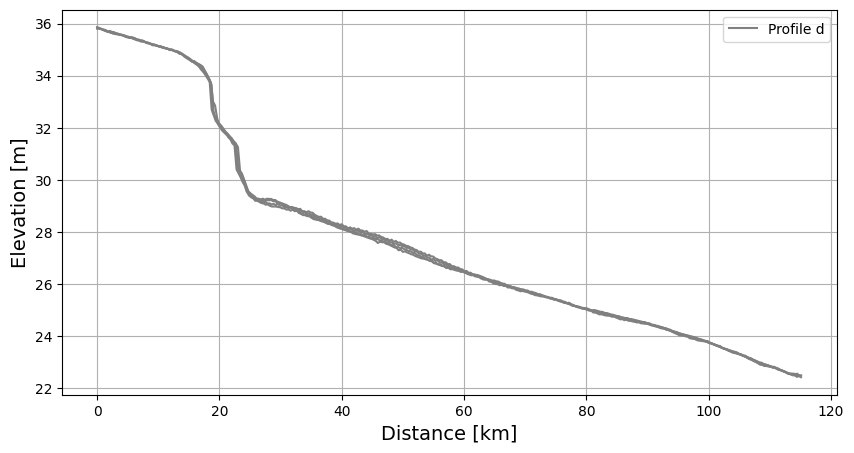

In [410]:
plt.figure(figsize=(10,5))
#plt.plot(distAa_1-3, elevAa_1+0.6, color='darkblue', linewidth=1.5,label='Profile a')
#plt.plot(distAa_2-3, elevAa_2+0.6, color='darkblue', linewidth=1.5)
#plt.plot(distAa_3-3, elevAa_3+0.6, color='darkblue', linewidth=1.5)
#plt.plot(distAa_4-3, elevAa_4+0.6, color='darkblue', linewidth=1.5)

#plt.plot(distAb_1, elevAb_1, color='blue', linewidth=1.5,label='Profile b')
#plt.plot(distAb_2, elevAb_2, color='blue', linewidth=1.5)
#plt.plot(distAb_3, elevAb_3, color='blue', linewidth=1.5)
#plt.plot(distAb_4, elevAb_4, color='blue', linewidth=1.5)

#plt.plot(distAc_1+6, elevAc_1-1.4, color='skyblue', linewidth=1.5,label='Profile c')
#plt.plot(distAc_2+6, elevAc_2-1.4, color='skyblue', linewidth=1.5)
#plt.plot(distAc_3+6, elevAc_3-1.4, color='skyblue', linewidth=1.5)
#plt.plot(distAc_4+6, elevAc_4-1.4, color='skyblue', linewidth=1.5)

plt.plot(distAd_1, elevAd_1-1.2, color='gray', linewidth=1.5,label='Profile d')
plt.plot(distAd_2, elevAd_2-1.2, color='gray', linewidth=1.5)
plt.plot(distAd_3, elevAd_3-1.2, color='gray', linewidth=1.5)
plt.plot(distAd_4, elevAd_4-1.2, color='gray', linewidth=1.5)

#plt.plot(distAe_1-5, elevAe_1-1.3, color='gold', linewidth=1.5,label='Profile e')
#plt.plot(distAe_2-5, elevAe_2-1.3, color='gold', linewidth=1.5)
#plt.plot(distAe_3-5, elevAe_3-1.3, color='gold', linewidth=1.5)
#plt.plot(distAe_4-5, elevAe_4-1.3, color='gold', linewidth=1.5)

plt.xlabel('Distance [km]', fontsize=14)
plt.ylabel('Elevation [m]', fontsize=14)
plt.grid(True)
plt.legend()

plt.savefig('Perfil_d.png')
plt.show()

#### Temporal evolution

In [411]:
topAd_Nov2010='../ProfilesTemporal/Pd_Nov2010.csv'
Ad_Nov2010=pd.read_csv(topAd_Nov2010)
distAd_Nov2010=np.array(Ad_Nov2010['distance'].tolist())
elevAd_Nov2010= np.array(Ad_Nov2010['elevation'].tolist())

topAd_Nov2011='../ProfilesTemporal/Pd_Nov2011.csv'
Ad_Nov2011=pd.read_csv(topAd_Nov2011)
distAd_Nov2011=np.array(Ad_Nov2011['distance'].tolist())
elevAd_Nov2011= np.array(Ad_Nov2011['elevation'].tolist())

topAd_Jan2012='../ProfilesTemporal/Pd_Jan2012.csv'
Ad_Jan2012=pd.read_csv(topAd_Jan2012)
distAd_Jan2012=np.array(Ad_Jan2012['distance'].tolist())
elevAd_Ja2012= np.array(Ad_Jan2012['elevation'].tolist())

topAd_Nov2012='../ProfilesTemporal/Pd_Nov2012.csv'
Ad_Nov2012=pd.read_csv(topAd_Nov2012)
distAd_Nov2012=np.array(Ad_Nov2012['distance'].tolist())
elevAd_Nov2012= np.array(Ad_Nov2012['elevation'].tolist())

topAd_Jan2013='../ProfilesTemporal/Pd_Jan2013.csv'
Ad_Jan2013=pd.read_csv(topAd_Jan2013)
distAd_Jan2013=np.array(Ad_Jan2013['distance'].tolist())
elevAd_Jan2013= np.array(Ad_Jan2013['elevation'].tolist())

topAd_Jan2014='../ProfilesTemporal/Pd_Jan2014.csv'
Ad_Jan2014=pd.read_csv(topAd_Jan2014)
distAd_Jan2014=np.array(Ad_Jan2014['distance'].tolist())
elevAd_Jan2014= np.array(Ad_Jan2014['elevation'].tolist())

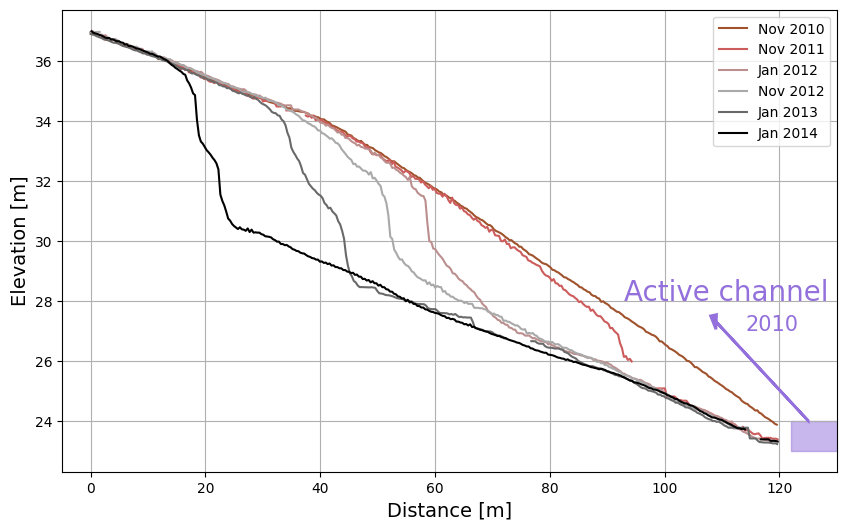

In [530]:
plt.figure(figsize=(10,6))

plt.plot(distAd_Nov2010, elevAd_Nov2010, color='sienna', linewidth=1.5,label='Nov 2010')
plt.plot(distAd_Nov2011, elevAd_Nov2011, color='indianred', linewidth=1.5,label='Nov 2011')
plt.plot(distAd_Jan2012, elevAd_Ja2012, color='rosybrown', linewidth=1.5,label='Jan 2012')
plt.plot(distAd_Nov2012, elevAd_Nov2012, color='darkgray', linewidth=1.5,label='Nov 2012')
plt.plot(distAd_Jan2013, elevAd_Jan2013, color='dimgray', linewidth=1.5,label='Jan 2013')
plt.plot(distAd_Jan2014, elevAd_Jan2014, color='black', linewidth=1.5,label='Jan 2014')

plt.text(93, 28, 'Active channel',color='mediumpurple',fontsize=20)
plt.text(114, 27, '2010',color='mediumpurple',fontsize=15)

plt.arrow(x=125, y=24,dx=-17, dy=3.5,color='mediumpurple',linewidth=2,head_width=0.5,head_length=1.,length_includes_head=True,zorder=10)
plt.fill_between([122, 140], 23, 24,color='mediumpurple', alpha=0.5)

plt.xlim(-5,130)
plt.xlabel('Distance [m]', fontsize=14)
plt.ylabel('Elevation [m]', fontsize=14)
plt.grid(True)
plt.legend()

plt.savefig('TempEv_dDisc.png')
plt.show()

In [413]:
aread_10_11, locd_10_11=AreaCalc(2, elevAd_Jan2014,elevAd_Nov2010,distAd_Nov2010,36,24)

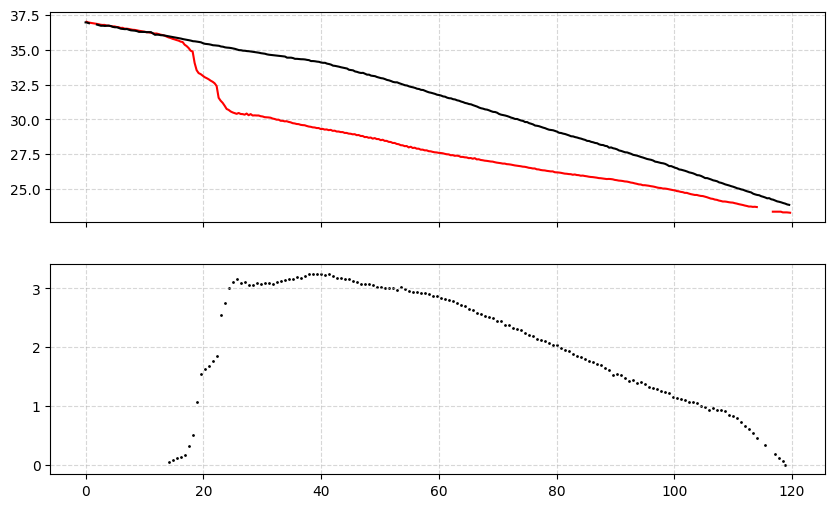

In [531]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(distAd_Jan2014, elevAd_Jan2014, color='red', linewidth=1.5)
ax1.plot(distAd_Nov2010,elevAd_Nov2010,color='black')
#ax1.axvline(x=0.33-0.13,linestyle='--',color='gray')
#ax1.axvline(x=0.7-0.13,linestyle='--',color='gray')
#ax1.axvline(x=78.4,linestyle='--',color='gray')
#ax2.axvline(x=78.4,linestyle='--',color='gray')

#ax1.axhline(y=40.6)
#ax1.axhline(y=33.4)

#ax1.axvline(x=52.4,linestyle='--',color='gray')
#ax2.axvline(x=52.4,linestyle='--',color='gray')

ax2.scatter(locd_10_11,aread_10_11,s=1,c='k')

#ax1.set_xlim(-2,5)

ax1.grid(True, which="both", linestyle="--", alpha=0.5)
ax2.grid(True, which="both", linestyle="--", alpha=0.5)

plt.savefig('Volume_Antarctica.png')
plt.show()

In [509]:
total_aread=np.array(aread_10_11).sum()
print('Total area lost: '+ str(total_aread)+'m^2')

Total area lost: 317.6566917150728m^2


### Profile j

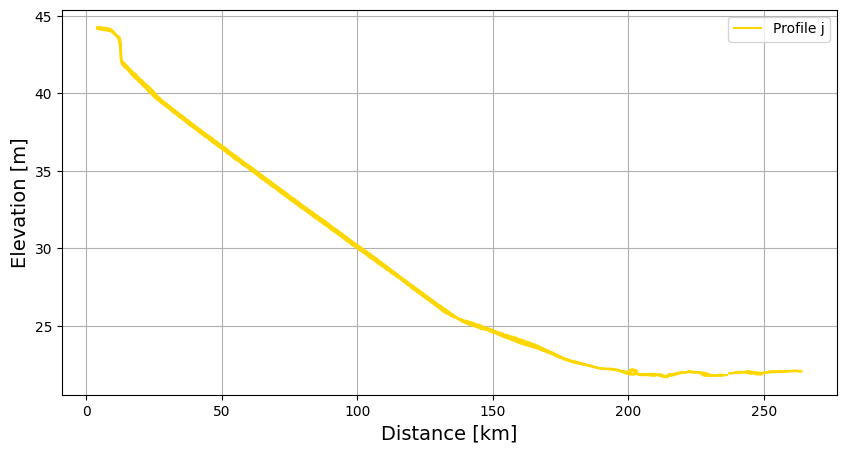

In [140]:
plt.figure(figsize=(10,5))
#plt.plot(distAf_1-6, elevAf_1, color='darkblue', linewidth=1.5,label='Profile f')
#plt.plot(distAf_2-6, elevAf_2, color='darkblue', linewidth=1.5)
#plt.plot(distAf_3-6, elevAf_3, color='darkblue', linewidth=1.5)
#plt.plot(distAf_4-6, elevAf_4, color='darkblue', linewidth=1.5)

#plt.plot(distAg_1, elevAg_1, color='blue', linewidth=1.5,label='Profile g')
#plt.plot(distAg_2, elevAg_2, color='blue', linewidth=1.5)
#plt.plot(distAg_3, elevAg_3, color='blue', linewidth=1.5)
#plt.plot(distAg_4, elevAg_4, color='blue', linewidth=1.5)

#plt.plot(distAh_1+6, elevAh_1+1.7, color='skyblue', linewidth=1.5,label='Profile h')
#plt.plot(distAh_2+6, elevAh_2+1.7, color='skyblue', linewidth=1.5)
#plt.plot(distAh_3+6, elevAh_3+1.7, color='skyblue', linewidth=1.5)
#plt.plot(distAh_4+6, elevAh_4+1.7, color='skyblue', linewidth=1.5)

#plt.plot(distAi_1+6, elevAi_1+2, color='gray', linewidth=1.5,label='Profile i')
#plt.plot(distAi_2+6, elevAi_2+2, color='gray', linewidth=1.5)
#plt.plot(distAi_3+6, elevAi_3+2, color='gray', linewidth=1.5)
#plt.plot(distAi_4+6, elevAi_4+2, color='gray', linewidth=1.5)

plt.plot(distAj_1+4, elevAj_1+0.8, color='gold', linewidth=1.5,label='Profile j')
plt.plot(distAj_2+4, elevAj_2+0.8, color='gold', linewidth=1.5)
plt.plot(distAj_3+4, elevAj_3+0.8, color='gold', linewidth=1.5)
plt.plot(distAj_4+4, elevAj_4+0.8, color='gold', linewidth=1.5)



plt.xlabel('Distance [km]', fontsize=14)
plt.ylabel('Elevation [m]', fontsize=14)
plt.grid(True)
plt.legend()

plt.savefig('Perfil_j.png')
plt.show()

#### Temporal Evolution

In [311]:
topAj_Nov2010='../ProfilesTemporal/Pj_Nov2010.csv'
Aj_Nov2010=pd.read_csv(topAj_Nov2010)
distAj_Nov2010=np.array(Aj_Nov2010['distance'].tolist())
elevAj_Nov2010= np.array(Aj_Nov2010['elevation'].tolist())

topAj_Nov2011='../ProfilesTemporal/Pj_Nov2011.csv'
Aj_Nov2011=pd.read_csv(topAj_Nov2011)
distAj_Nov2011=np.array(Aj_Nov2011['distance'].tolist())
elevAj_Nov2011= np.array(Aj_Nov2011['elevation'].tolist())

topAj_Jan2012='../ProfilesTemporal/Pj_Jan2012.csv'
Aj_Jan2012=pd.read_csv(topAj_Jan2012)
distAj_Jan2012=np.array(Aj_Jan2012['distance'].tolist())
elevAj_Ja2012= np.array(Aj_Jan2012['elevation'].tolist())

topAj_Nov2012='../ProfilesTemporal/Pj_Nov2012.csv'
Aj_Nov2012=pd.read_csv(topAj_Nov2012)
distAj_Nov2012=np.array(Aj_Nov2012['distance'].tolist())
elevAj_Nov2012= np.array(Aj_Nov2012['elevation'].tolist())

topAj_Jan2013='../ProfilesTemporal/Pj_Jan2013.csv'
Aj_Jan2013=pd.read_csv(topAj_Jan2013)
distAj_Jan2013=np.array(Aj_Jan2013['distance'].tolist())
elevAj_Jan2013= np.array(Aj_Jan2013['elevation'].tolist())

topAj_Jan2014='../ProfilesTemporal/Pj_Jan2014.csv'
Aj_Jan2014=pd.read_csv(topAj_Jan2014)
distAj_Jan2014=np.array(Aj_Jan2014['distance'].tolist())
elevAj_Jan2014= np.array(Aj_Jan2014['elevation'].tolist())

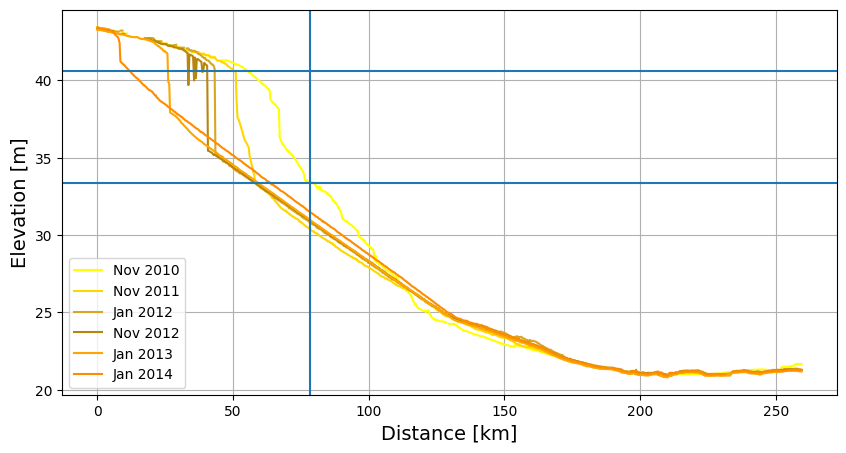

In [372]:
plt.figure(figsize=(10,5))

plt.plot(distAj_Nov2010, elevAj_Nov2010, color='yellow', linewidth=1.5,label='Nov 2010')
plt.plot(distAj_Nov2011, elevAj_Nov2011, color='gold', linewidth=1.5,label='Nov 2011')
plt.plot(distAj_Jan2012, elevAj_Ja2012, color='goldenrod', linewidth=1.5,label='Jan 2012')
plt.plot(distAj_Nov2012, elevAj_Nov2012, color='darkgoldenrod', linewidth=1.5,label='Nov 2012')
plt.plot(distAj_Jan2013, elevAj_Jan2013, color='orange', linewidth=1.5,label='Jan 2013')
plt.plot(distAj_Jan2014, elevAj_Jan2014, color='darkorange', linewidth=1.5,label='Jan 2014')
plt.axhline(y=40.6)
plt.axhline(y=33.4)
plt.axvline(x=78.4)

plt.xlabel('Distance [km]', fontsize=14)
plt.ylabel('Elevation [m]', fontsize=14)
plt.grid(True)
plt.legend()

plt.savefig('TempEv_j.png')
plt.show()

In [401]:
areaj_10_11, locj_10_11=AreaCalc(2, elevAj_Nov2011,elevAj_Nov2010,distAj_Nov2010,40.6,33.4)

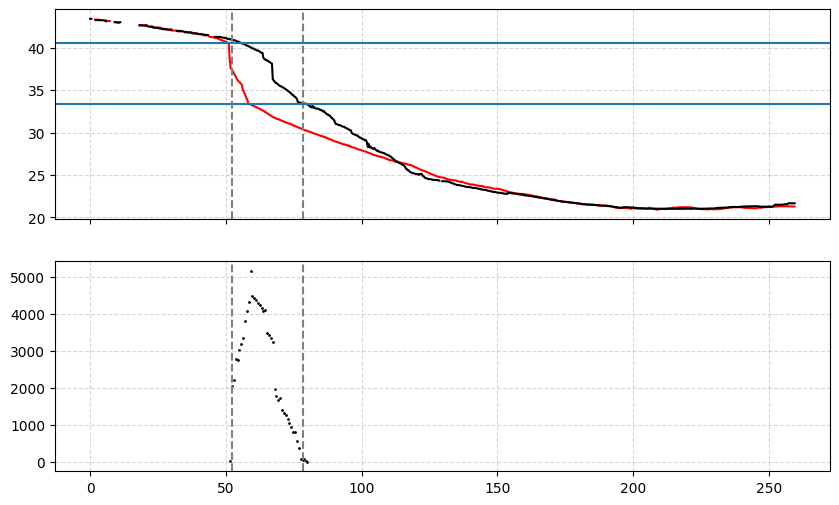

In [400]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(distAj_Nov2011, elevAj_Nov2011, color='red', linewidth=1.5)
ax1.plot(distAj_Nov2010,elevAj_Nov2010,color='black')
#ax1.axvline(x=0.33-0.13,linestyle='--',color='gray')
#ax1.axvline(x=0.7-0.13,linestyle='--',color='gray')
ax1.axvline(x=78.4,linestyle='--',color='gray')
ax2.axvline(x=78.4,linestyle='--',color='gray')

ax1.axhline(y=40.6)
ax1.axhline(y=33.4)

ax1.axvline(x=52.4,linestyle='--',color='gray')
ax2.axvline(x=52.4,linestyle='--',color='gray')


ax2.scatter(locj_10_11,areaj_10_11,s=1,c='k')

#ax1.set_xlim(-2,5)

ax1.grid(True, which="both", linestyle="--", alpha=0.5)
ax2.grid(True, which="both", linestyle="--", alpha=0.5)

### Profile m

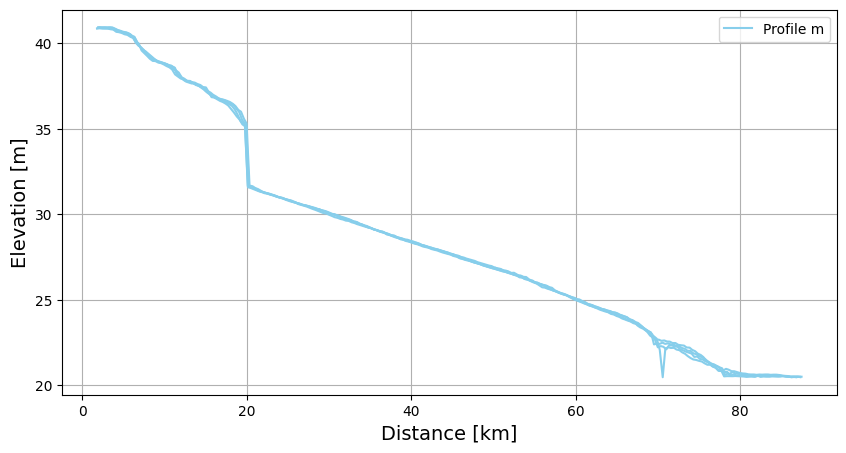

In [141]:
plt.figure(figsize=(10,5))
#plt.plot(distAk_1+2., elevAk_1-1, color='darkblue', linewidth=1.5,label='Profile k')
#plt.plot(distAk_2+2, elevAk_2-1, color='darkblue', linewidth=1.5)
#plt.plot(distAk_3+2, elevAk_3-1, color='darkblue', linewidth=1.5)
#plt.plot(distAk_4+2, elevAk_4-1, color='darkblue', linewidth=1.5)

#plt.plot(distAl_1, elevAl_1, color='blue', linewidth=1.5,label='Profile l')
#plt.plot(distAl_2, elevAl_2, color='blue', linewidth=1.5)
#plt.plot(distAl_3, elevAl_3, color='blue', linewidth=1.5)
#plt.plot(distAl_4, elevAl_4, color='blue', linewidth=1.5)

plt.plot(distAm_1+1.8, elevAm_1+0.8, color='skyblue', linewidth=1.5,label='Profile m')
plt.plot(distAm_2+1.8, elevAm_2+0.8, color='skyblue', linewidth=1.5)
plt.plot(distAm_3+1.8, elevAm_3+0.8, color='skyblue', linewidth=1.5)
plt.plot(distAm_4+1.8, elevAm_4+0.8, color='skyblue', linewidth=1.5)




plt.xlabel('Distance [km]', fontsize=14)
plt.ylabel('Elevation [m]', fontsize=14)
plt.grid(True)
plt.legend()

plt.savefig('Perfil_m.png')
plt.show()

#### Temporal evolution

In [155]:
topAm_Nov2010='../ProfilesTemporal/Pm_Nov2010.csv'
Am_Nov2010=pd.read_csv(topAm_Nov2010)
distAm_Nov2010=np.array(Am_Nov2010['distance'].tolist())
elevAm_Nov2010= np.array(Am_Nov2010['elevation'].tolist())

topAm_Nov2011='../ProfilesTemporal/Pm_Nov2011.csv'
Am_Nov2011=pd.read_csv(topAm_Nov2011)
distAm_Nov2011=np.array(Am_Nov2011['distance'].tolist())
elevAm_Nov2011= np.array(Am_Nov2011['elevation'].tolist())

topAm_Jan2012='../ProfilesTemporal/Pm_Jan2012.csv'
Am_Jan2012=pd.read_csv(topAm_Jan2012)
distAm_Jan2012=np.array(Am_Jan2012['distance'].tolist())
elevAm_Ja2012= np.array(Am_Jan2012['elevation'].tolist())

topAm_Nov2012='../ProfilesTemporal/Pm_Nov2012.csv'
Am_Nov2012=pd.read_csv(topAm_Nov2012)
distAm_Nov2012=np.array(Am_Nov2012['distance'].tolist())
elevAm_Nov2012= np.array(Am_Nov2012['elevation'].tolist())

topAm_Jan2013='../ProfilesTemporal/Pm_Jan2013.csv'
Am_Jan2013=pd.read_csv(topAm_Jan2013)
distAm_Jan2013=np.array(Am_Jan2013['distance'].tolist())
elevAm_Jan2013= np.array(Am_Jan2013['elevation'].tolist())

topAm_Jan2014='../ProfilesTemporal/Pm_Jan2014.csv'
Am_Jan2014=pd.read_csv(topAm_Jan2014)
distAm_Jan2014=np.array(Am_Jan2014['distance'].tolist())
elevAm_Jan2014= np.array(Am_Jan2014['elevation'].tolist())

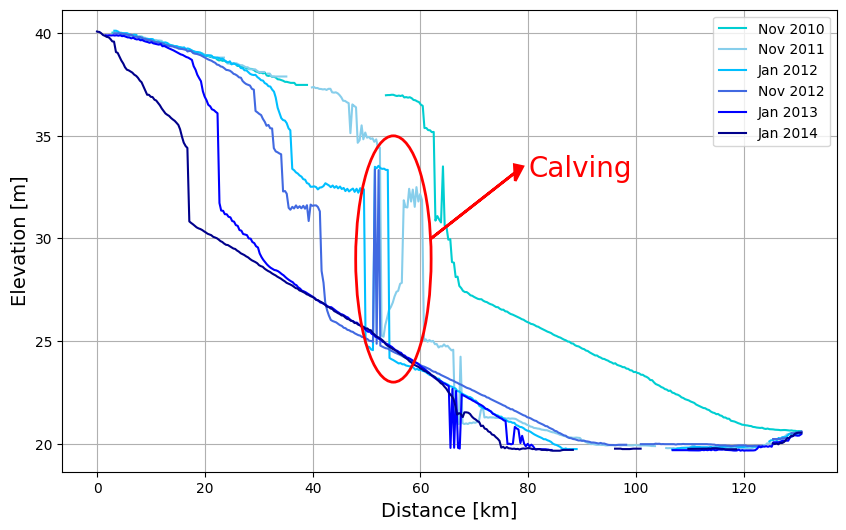

In [497]:
plt.figure(figsize=(10,6))

plt.plot(distAm_Nov2010, elevAm_Nov2010, color='darkturquoise', linewidth=1.5,label='Nov 2010')
plt.plot(distAm_Nov2011, elevAm_Nov2011, color='skyblue', linewidth=1.5,label='Nov 2011')
plt.plot(distAm_Jan2012, elevAm_Ja2012, color='deepskyblue', linewidth=1.5,label='Jan 2012')
plt.plot(distAm_Nov2012, elevAm_Nov2012, color='royalblue', linewidth=1.5,label='Nov 2012')
plt.plot(distAm_Jan2013, elevAm_Jan2013, color='blue', linewidth=1.5,label='Jan 2013')
plt.plot(distAm_Jan2014, elevAm_Jan2014, color='darkblue', linewidth=1.5,label='Jan 2014')

plt.text(80, 33, 'Calving',color='red',fontsize=20)

ellipse = Ellipse(
    xy=(55, 29),  # Center of the ellipse
    width=14,                 # Total width (x direction)
    height=12,                 # Total height (y direction)
    angle=0,                  # Rotation in degrees
    edgecolor='red',
    facecolor='none',
    linewidth=2,
    zorder=10
)
plt.gca().add_patch(ellipse)

plt.arrow(x=62, y=30,dx=17, dy=3.5,color='red',linewidth=2,head_width=0.8,head_length=1.5,length_includes_head=True,zorder=10)

plt.xlabel('Distance [km]', fontsize=14)
plt.ylabel('Elevation [m]', fontsize=14)
plt.grid(True)
plt.legend()

plt.savefig('TempEv_mCal.png')
plt.show()

### Profile s

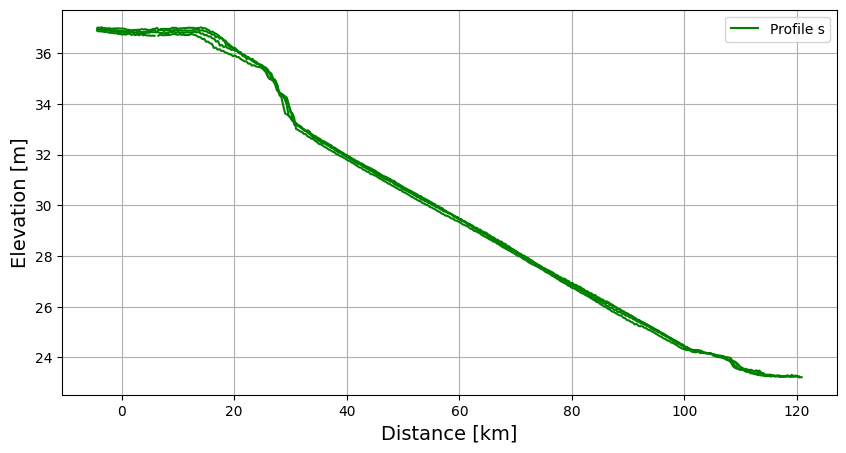

In [319]:
plt.figure(figsize=(10,5))
#plt.plot(distAn_1+10, elevAn_1-2, color='darkblue', linewidth=1.5,label='Profile n')
#plt.plot(distAn_2+10, elevAn_2-2, color='darkblue', linewidth=1.5)
#plt.plot(distAn_3+10, elevAn_3-2, color='darkblue', linewidth=1.5)
#plt.plot(distAn_4+10, elevAn_4-2, color='darkblue', linewidth=1.5)

#plt.plot(distAo_1, elevAo_1, color='blue', linewidth=1.5,label='Profile o')
#plt.plot(distAo_2, elevAo_2, color='blue', linewidth=1.5)
#plt.plot(distAo_3, elevAo_3, color='blue', linewidth=1.5)
#plt.plot(distAo_4, elevAo_4, color='blue', linewidth=1.5)

#plt.plot(distAp_1+11, elevAp_1+0.7, color='skyblue', linewidth=1.5,label='Profile p')
#plt.plot(distAp_2+11, elevAp_2+0.7, color='skyblue', linewidth=1.5)
#plt.plot(distAp_3+11, elevAp_3+0.7, color='skyblue', linewidth=1.5)
#plt.plot(distAp_4+11, elevAp_4+0.7, color='skyblue', linewidth=1.5)

#plt.plot(distAq_1+2, elevAq_1+2.8, color='gray', linewidth=1.5,label='Profile q')
#plt.plot(distAq_2+2, elevAq_2+2.8, color='gray', linewidth=1.5)
#plt.plot(distAq_3+2, elevAq_3+2.8, color='gray', linewidth=1.5)
#plt.plot(distAq_4+2, elevAq_4+2.8, color='gray', linewidth=1.5)

#plt.plot(distAr_1+2, elevAr_1+3.6, color='gold', linewidth=1.5,label='Profile r')
#plt.plot(distAr_2+2, elevAr_2+3.6, color='gold', linewidth=1.5)
#plt.plot(distAr_3+2, elevAr_3+3.6, color='gold', linewidth=1.5)
#plt.plot(distAr_4+2, elevAr_4+3.6, color='gold', linewidth=1.5)

plt.plot(distAs_1[40:]-18, elevAs_1[40:]+4.5, color='green', linewidth=1.5,label='Profile s')
plt.plot(distAs_2[40:]-18, elevAs_2[40:]+4.5, color='green', linewidth=1.5)
plt.plot(distAs_3[40:]-18, elevAs_3[40:]+4.5, color='green', linewidth=1.5)
plt.plot(distAs_4[40:]-18, elevAs_4[40:]+4.5, color='green', linewidth=1.5)

#plt.plot(distAt_1[10:]-12, elevAt_1[10:]+7.7, color='coral', linewidth=1.5,label='Profile t')
#plt.plot(distAt_2[10:]-12, elevAt_2[10:]+7.7, color='coral', linewidth=1.5)
#plt.plot(distAt_3[10:]-12, elevAt_3[10:]+7.7, color='coral', linewidth=1.5)
#plt.plot(distAt_4[10:]-12, elevAt_4[10:]+7.7, color='coral', linewidth=1.5)



plt.xlabel('Distance [km]', fontsize=14)
plt.ylabel('Elevation [m]', fontsize=14)
plt.grid(True)
plt.legend()

plt.savefig('Perfil_s.png')
plt.show()

#### Temporal evolution

In [320]:
topAs_Nov2010='../ProfilesTemporal/Ps_Nov2010.csv'
As_Nov2010=pd.read_csv(topAs_Nov2010)
distAs_Nov2010=np.array(As_Nov2010['distance'].tolist())
elevAs_Nov2010= np.array(As_Nov2010['elevation'].tolist())

topAs_Nov2011='../ProfilesTemporal/Ps_Nov2011.csv'
As_Nov2011=pd.read_csv(topAs_Nov2011)
distAs_Nov2011=np.array(As_Nov2011['distance'].tolist())
elevAs_Nov2011= np.array(As_Nov2011['elevation'].tolist())

topAs_Jan2012='../ProfilesTemporal/Ps_Jan2012.csv'
As_Jan2012=pd.read_csv(topAs_Jan2012)
distAs_Jan2012=np.array(As_Jan2012['distance'].tolist())
elevAs_Ja2012= np.array(As_Jan2012['elevation'].tolist())

topAs_Nov2012='../ProfilesTemporal/Ps_Nov2012.csv'
As_Nov2012=pd.read_csv(topAs_Nov2012)
distAs_Nov2012=np.array(As_Nov2012['distance'].tolist())
elevAs_Nov2012= np.array(As_Nov2012['elevation'].tolist())

topAs_Jan2013='../ProfilesTemporal/Ps_Jan2013.csv'
As_Jan2013=pd.read_csv(topAs_Jan2013)
distAs_Jan2013=np.array(As_Jan2013['distance'].tolist())
elevAs_Jan2013= np.array(As_Jan2013['elevation'].tolist())

topAs_Jan2014='../ProfilesTemporal/Ps_Jan2014.csv'
As_Jan2014=pd.read_csv(topAs_Jan2014)
distAs_Jan2014=np.array(As_Jan2014['distance'].tolist())
elevAs_Jan2014= np.array(As_Jan2014['elevation'].tolist())

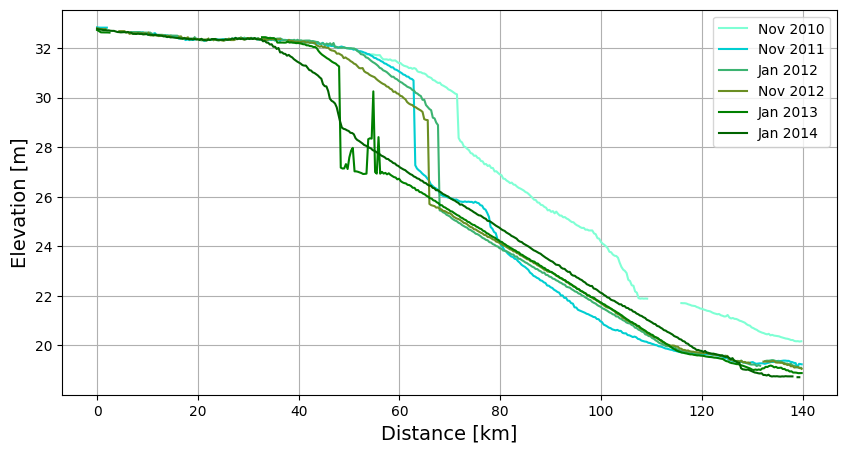

In [328]:
plt.figure(figsize=(10,5))

plt.plot(distAs_Nov2010, elevAs_Nov2010, color='aquamarine', linewidth=1.5,label='Nov 2010')
plt.plot(distAs_Nov2011, elevAs_Nov2011, color='darkturquoise', linewidth=1.5,label='Nov 2011')
plt.plot(distAs_Jan2012, elevAs_Ja2012, color='mediumseagreen', linewidth=1.5,label='Jan 2012')
plt.plot(distAs_Nov2012, elevAs_Nov2012, color='olivedrab', linewidth=1.5,label='Nov 2012')
plt.plot(distAs_Jan2013, elevAs_Jan2013, color='green', linewidth=1.5,label='Jan 2013')
plt.plot(distAs_Jan2014, elevAs_Jan2014, color='darkgreen', linewidth=1.5,label='Jan 2014')

plt.xlabel('Distance [km]', fontsize=14)
plt.ylabel('Elevation [m]', fontsize=14)
plt.grid(True)
plt.legend()

plt.savefig('TempEv_s.png')
plt.show()

## Insolation stuff

In [424]:
df = pd.read_excel("../GARmet_all.xlsx", sheet_name="Sheet1")

#df = pd.read_excel("your_file.xlsx", sheet_name=0)


df

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,Location Code,Date,Year.Date,AirT Proc. Data,AirTemp Flag,RH Proc. Data,RH Flag,SwRad_FacingSouth,Flag,SwRad_FacingNorth,...,Unnamed: 64,DJP Comp,cm/year,r2,cm/day,Unnamed: 69,Melt Period Comp,cm/year.1,r2.1,cm/day.1
0,GAFM,2010-12-06 16:30:00,2010.933390,0.150000,NaN,37.50,NaN,66.700,NaN,266.20,...,NaN,DJF Summer 10-11,2031.992489,0.140448,0.168753,NaN,DJF Summer 10-11,2031.992489,0.072083,0.168753
1,GAFM,2010-12-06 16:45:00,2010.933419,0.070000,NaN,37.80,NaN,64.500,NaN,217.80,...,NaN,Winter (M-8/22/11) 11,47.216267,0.016157,0.000739,NaN,NaN,NaN,NaN,NaN
2,GAFM,2010-12-06 17:00:00,2010.933447,-0.180000,NaN,38.10,NaN,65.300,NaN,142.70,...,NaN,DJF Summer 11/12,646.722738,0.407747,0.059767,NaN,DJF Summer 11/12,-0.311997,0.154810,-0.000029
3,GAFM,2010-12-06 17:15:00,2010.933476,-0.150000,NaN,38.80,NaN,101.200,NaN,90.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,GAFM,2010-12-06 17:30:00,2010.933505,-0.710000,NaN,47.40,NaN,148.200,NaN,78.70,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37313,GAFM,2011-12-30 15:15:00,2011.996261,10.055004,NaN,38.24,NaN,81.600,NaN,529.20,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
37314,GAFM,2011-12-30 15:30:00,2011.996290,9.955468,NaN,39.70,NaN,79.100,NaN,470.60,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
37315,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
37316,NaN,NaT,NaN,NaN,NaN,NaN,NaN,19.143,NaN,38.64,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [284]:
sf=np.array(df['Net Rad'])
dist=np.array(df['IceSurfChange(cm)'])
#dist=np.array(df[''])
date=np.array(df['Date'])
dist

array([ 0., nan,  0., ..., nan, nan, nan], shape=(37318,))

In [285]:

sum_sf=[]
summed=0
for i in sf:
    summed+=i
    sum_sf.append(summed)

np.array(sum_sf)

array([162.1, 301.8, 367.4, ...,   nan,   nan,   nan], shape=(37318,))

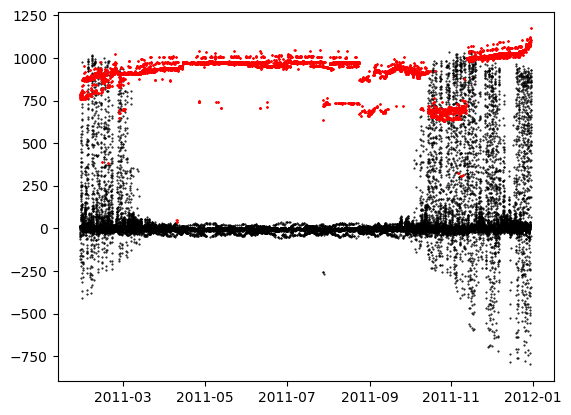

In [286]:
plt.scatter(date[5000:],sf[5000:],marker='.',color='black',s=1)
plt.scatter(date[5000:],dist[5000:],marker='.',color='red',s=1)
#plt.scatter(date,sum_sf)

In [434]:
len(date)

37318

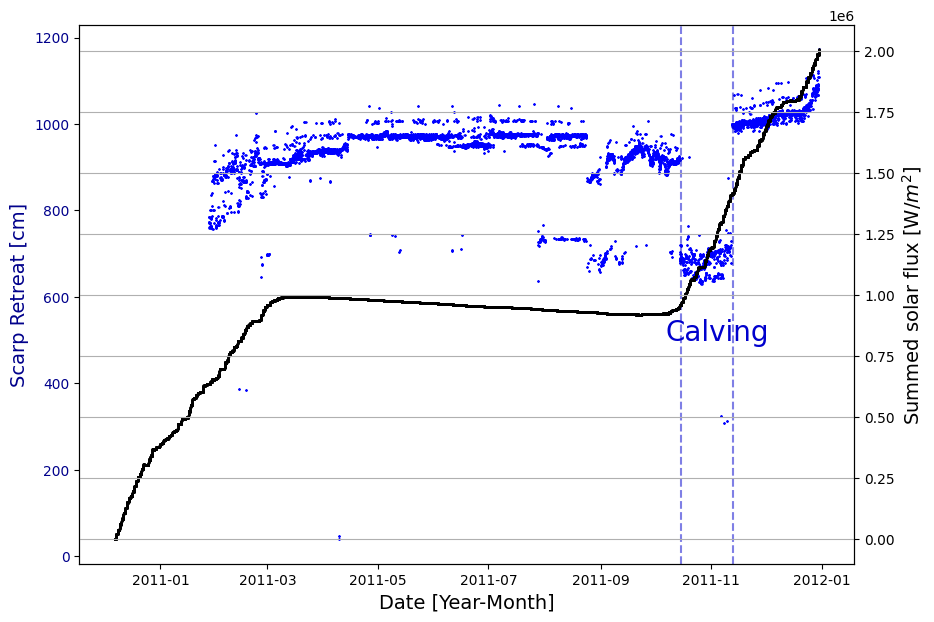

In [457]:
fig, ax1=plt.subplots(figsize=(10,7))

ax1.scatter(date[5000:],dist[5000:],marker='.',color='blue',s=1)

ax1.set_ylabel('Scarp Retreat [cm]',fontsize=14,color='darkblue')
ax1.set_xlabel('Date [Year-Month]',fontsize=14)
ax1.tick_params(axis='y',labelcolor='darkblue')

ax1.axvline(date[30000],color='mediumblue', linestyle='--',alpha=0.5)
ax1.axvline(date[32750],color='mediumblue', linestyle='--',alpha=0.5)
ax1.text(date[29200], 500, 'Calving',color='mediumblue',fontsize=20)


ax2=ax1.twinx()
ax2.scatter(date,sum_sf,marker='.',color='black',s=1)
ax2.set_ylabel(r'Summed solar flux [W/$m^2$]',fontsize=14,color='black')
ax2.tick_params(axis='y',labelcolor='black')



plt.grid(True)
plt.savefig('SolarFlux_AntCal.png')
plt.show()